# Stage 7 — Final Model Testing (2025–2026)

**SIM Montréal — Intervention Demand Forecasting**

**Objective:** Evaluate the previously selected fixed equal-weight Ensemble on the reserved test period against the selected same-weekday Baseline and individual models.

- **Unit:** Division × calendar day, Divisions 1–6.
- **Final test:** January 1, 2025 through September 24, 2026.
- **Forecast timing:** A forecast for day D is prepared on D−1. Historical counts are usable only through D−3.
- **Monthly updates:** Fit models with target dates through the cutoff three days before the first date of each test month. The model configuration and ensemble weights remain fixed.
- **Evaluation:** MAE, Bias (prediction − actual), population error standard deviation and variance, division and year breakdowns, and High demand alerts.

**Model Reproducibility:** Stage 7 uses the model configurations and preprocessing established in Stage 5, along with the fixed equal-weight ensemble selected in Stage 6.

Models are updated monthly using only historical information available before each training cutoff. Test observations may be used for subsequent monthly model updates once they are historically available. Test performance results are not used for model selection or parameter tuning.


## 7.1 Install and import libraries

Use the same modeling libraries as Stage 5, including the categorical encoding and numerical imputation used by Linear Regression.

In [ ]:
# LightGBM and CatBoost are project dependencies (pyproject.toml): no install needed in the repo.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import lightgbm as lgb
from catboost import CatBoostRegressor

pd.set_option("display.max_columns", 30)


## 7.2 Locked Test Configuration

The selected Stage 6 method is the **Fixed Equal-Weight Ensemble** of Linear Regression, LightGBM, and CatBoost. The Baseline uses the last **13 valid same-weekday observations**, respecting the D−3 cutoff.

**Model Configuration:**

- **Linear Regression:** Numerical median imputation and one-hot encoding for `DIVISION`.
- **LightGBM:** 100 trees, learning rate of 0.05, 15 leaves, and categorical `DIVISION`.
- **CatBoost:** 100 iterations, learning rate of 0.05, depth of 4, RMSE loss, and categorical `DIVISION`.

The Ensemble combines the three model predictions using equal weights of 1/3. Predictions are not clipped or adjusted after they are generated.

All model configurations, preprocessing methods, Baseline settings, and Ensemble weights remain fixed throughout final testing. Test performance results will not be used to modify these decisions.


In [ ]:
TEST_START = pd.Timestamp("2025-01-01")
TEST_END = pd.Timestamp("2026-09-24")
DIVISIONS = [1, 2, 3, 4, 5, 6]
BASELINE_WINDOW = 13

ENSEMBLE_WEIGHTS = {
    "Linear Regression": 1 / 3,
    "LightGBM": 1 / 3,
    "CatBoost": 1 / 3
}

LIGHTGBM_PARAMS = dict(
    objective="regression",
    n_estimators=100,
    learning_rate=0.05,
    num_leaves=15,
    random_state=42,
    verbosity=-1
)

CATBOOST_PARAMS = dict(
    iterations=100,
    learning_rate=0.05,
    depth=4,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=2
)

CATEGORICAL_FEATURES = ["DIVISION"]
NUMERICAL_FEATURES = [
    "DayOfWeek", "Month", "DayOfMonth", "IsWeekend", "DayOfYear",
    "Lag_3", "Lag_7", "Lag_14", "Lag_28",
    "Rolling_Mean_7", "Rolling_Mean_14"
]
FEATURE_COLS = CATEGORICAL_FEATURES + NUMERICAL_FEATURES
TARGET_COL = "Intervention_Count"

assert len(FEATURE_COLS) == 12
assert np.isclose(sum(ENSEMBLE_WEIGHTS.values()), 1.0)
print("Locked test period:", TEST_START.date(), "to", TEST_END.date())
print("Baseline window:", BASELINE_WINDOW)
print("Features:", len(FEATURE_COLS))
print("Ensemble weights:", ENSEMBLE_WEIGHTS)

Locked test period: 2025-01-01 to 2026-09-24
Baseline window: 13
Features: 12
Ensemble weights: {'Linear Regression': 0.3333333333333333, 'LightGBM': 0.3333333333333333, 'CatBoost': 0.3333333333333333}



## 7.3 Load the Complete Stage 3 Feature Dataset

This section loads `SIM_Features_Complete.csv`, the complete feature dataset created in Stage 3.

The dataset contains daily intervention counts and predictive features for SIM Divisions 1 through 6, covering January 1, 2020 through September 24, 2026.

The complete dataset preserves the six unknown intervention counts from December 31, 2024. These missing values are important for maintaining correct calendar alignment when using historical features.

The dataset will be sorted by division and date to maintain chronological order.

The structure and integrity of the data will be verified in the following section.


In [ ]:

feature_file = "../../data/interim/final/SIM_Features_Complete.csv"

df = pd.read_csv(feature_file, parse_dates=["Date"])

df = df.sort_values(
    ["DIVISION", "Date"]
).reset_index(drop=True)

print("Dataset dimensions:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head(3))


Dataset dimensions: (14754, 14)
Columns: ['Date', 'DIVISION', 'Intervention_Count', 'DayOfWeek', 'Month', 'DayOfMonth', 'IsWeekend', 'DayOfYear', 'Lag_3', 'Lag_7', 'Lag_14', 'Lag_28', 'Rolling_Mean_7', 'Rolling_Mean_14']


,Date,DIVISION,Intervention_Count,DayOfWeek,Month,DayOfMonth,IsWeekend,DayOfYear,Lag_3,Lag_7,Lag_14,Lag_28,Rolling_Mean_7,Rolling_Mean_14
0,2020-01-01,1,35.0,2,1,1,0,1,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-01-02,1,24.0,3,1,2,0,2,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-01-03,1,18.0,4,1,3,0,3,NaN,NaN,NaN,NaN,NaN,NaN



## 7.4 Dataset Integrity and Chronological Checks

This section verifies that the complete feature dataset preserves the structure established in Stage 3.

The validation checks:

1. The required columns and six operational divisions.
2. The expected date range and continuous division-day calendar.
3. The absence of duplicate division-date combinations.
4. The preservation of the six unknown targets from December 31, 2024.
5. The availability of actual intervention counts throughout the final test period.

Missing historical observations remain missing rather than being replaced with zero.

These checks establish the structural integrity of the dataset. The D−3 alignment of historical predictive features will be verified separately in Section 7.5.


In [ ]:
required_columns = ["Date", TARGET_COL] + FEATURE_COLS
missing_columns = [col for col in required_columns if col not in df.columns]
assert not missing_columns, f"Missing Stage 3 columns: {missing_columns}"

assert not df.duplicated(["Date", "DIVISION"]).any(), "Duplicate division-date keys."
assert df["Date"].notna().all()
assert df["DIVISION"].notna().all()
assert set(df["DIVISION"].unique()) == set(DIVISIONS)
assert df["Date"].min() == pd.Timestamp("2020-01-01")
assert df["Date"].max() == TEST_END
assert pd.api.types.is_numeric_dtype(df[TARGET_COL])
assert (df[TARGET_COL].dropna() >= 0).all()

expected_dates = pd.date_range("2020-01-01", TEST_END, freq="D")
expected_keys = pd.MultiIndex.from_product(
    [DIVISIONS, expected_dates], names=["DIVISION", "Date"]
)
actual_keys = pd.MultiIndex.from_frame(df[["DIVISION", "Date"]])
assert len(actual_keys) == len(expected_keys)
assert expected_keys.difference(actual_keys).empty, "Missing calendar observations."

unknown_targets = df[df[TARGET_COL].isna()]
assert len(unknown_targets) == 6, "Expected six unknown targets from Stage 1."
assert (unknown_targets["Date"] == pd.Timestamp("2024-12-31")).all()
assert set(unknown_targets["DIVISION"]) == set(DIVISIONS)

assert df[NUMERICAL_FEATURES].apply(pd.to_numeric, errors="coerce").notna().sum().sum() > 0

available_test = df.loc[df["Date"].between(TEST_START, TEST_END)]
assert available_test[TARGET_COL].notna().all(), "Missing targets in the test period."

print("Continuous division-day calendar: PASSED")
print("Unknown targets preserved:", len(unknown_targets))
print("Test division-day observations:", len(available_test))
print("Missing feature values in test:", int(available_test[FEATURE_COLS].isna().any(axis=1).sum()))

Continuous division-day calendar: PASSED
Unknown targets preserved: 6
Test division-day observations: 3792
Missing feature values in test: 90



### Methodological Observation

The dataset integrity checks passed. The final test period contains 3,792 division-day observations with known target values.

However, 90 observations have at least one missing predictive feature.

These missing features are explained by the six unknown intervention counts from December 31, 2024, which affect historical lag and rolling mean calculations during January 2025.

The affected dates are January 3 through January 16, and January 28. This represents 15 calendar days across six divisions, resulting in 90 observations.

These observations have known target values and remain valid for final evaluation. They should not be removed simply because some historical predictors are unavailable.

Each model will handle missing predictive values using the preprocessing methods established in Stage 5.

This preserves the complete test period and maintains consistency with the original modeling methodology.



## 7.5 Verify Historical Feature Alignment (D−3)

This section verifies that the historical predictive features created in Stage 3 are correctly aligned with the original intervention counts.

The validation checks:

1. The four lag features (`Lag_3`, `Lag_7`, `Lag_14`, and `Lag_28`) against their corresponding historical dates.
2. The 7-day and 14-day rolling means, calculated using complete historical windows ending at D−3.
3. The preservation of missing values when the required historical observations are unavailable.

All historical calculations are performed separately for each operational division.

These checks help confirm that the historical features respect the D−3 information cutoff and do not use intervention counts from D, D−1, or D−2.


In [ ]:
daily = df[["Date", "DIVISION", TARGET_COL]].copy()

for lag in [3, 7, 14, 28]:
    reference = daily.copy()
    reference["Date"] = reference["Date"] + pd.Timedelta(days=lag)
    reference = reference.rename(columns={TARGET_COL: "Expected_Lag"})
    comparison = df[["Date", "DIVISION", f"Lag_{lag}"]].merge(
        reference, on=["Date", "DIVISION"], how="left", validate="one_to_one"
    )
    assert np.allclose(
        comparison[f"Lag_{lag}"], comparison["Expected_Lag"], equal_nan=True
    ), f"Lag_{lag} does not match the expected historical date."

for window in [7, 14]:
    reference = daily.copy()
    reference["Expected_Rolling"] = (
        reference.groupby("DIVISION")[TARGET_COL]
        .transform(lambda counts: counts.shift(3).rolling(window, min_periods=window).mean())
    )
    comparison = df[["Date", "DIVISION", f"Rolling_Mean_{window}"]].merge(
        reference[["Date", "DIVISION", "Expected_Rolling"]],
        on=["Date", "DIVISION"], how="left", validate="one_to_one"
    )
    assert np.allclose(
        comparison[f"Rolling_Mean_{window}"],
        comparison["Expected_Rolling"], equal_nan=True
    ), f"Rolling_Mean_{window} does not match the D-3 feature definition."

print("D-3 feature alignment: PASSED")

D-3 feature alignment: PASSED



### Methodological Observation

The historical feature alignment checks passed for all four lag features and both rolling mean features.

The lag features match their corresponding historical intervention counts, while the rolling means match the complete historical windows ending at D−3. Missing historical values are also preserved correctly.

These results confirm that the stored historical features follow the definitions established in Stage 3 and do not incorporate intervention counts from D, D−1, or D−2.

This is an important validation against data leakage. However, it does not independently verify the monthly model training cutoffs or the prediction process. Those conditions must also be respected during final testing.



## 7.6 Prepare the Three Model Implementations

This section prepares the three Machine Learning models using the preprocessing methods and configurations established in Stage 5.

Each model uses the same 12 predictive features but handles categorical and missing numerical values differently.

- **Linear Regression:** Uses a Pipeline with median imputation for numerical features and one-hot encoding for `DIVISION`. Preprocessing is fitted using only the training data.
- **LightGBM:** Uses `DIVISION` as a pandas categorical feature with the six operational divisions defined as categories. Missing numerical values are handled by LightGBM.
- **CatBoost:** Uses `DIVISION` as a categorical identifier represented by text. Missing numerical values are handled by CatBoost.

The target variable is not imputed, and model predictions are used without clipping or additional adjustments.

These implementations preserve the modeling decisions established during development and validation.


In [ ]:
division_categories = [1, 2, 3, 4, 5, 6]

def create_linear_model():
    numerical_preprocessing = SimpleImputer(strategy="median")
    categorical_preprocessing = OneHotEncoder(handle_unknown="ignore")
    preprocessor = ColumnTransformer(
        transformers=[
            ("numerical", numerical_preprocessing, NUMERICAL_FEATURES),
            ("categorical", categorical_preprocessing, CATEGORICAL_FEATURES)
        ]
    )
    return Pipeline([
        ("preprocessing", preprocessor),
        ("regression", LinearRegression())
    ])

def prepare_lightgbm_features(features):
    prepared = features.copy()
    prepared["DIVISION"] = pd.Categorical(
        prepared["DIVISION"], categories=division_categories
    )
    return prepared

def prepare_catboost_features(features):
    prepared = features.copy()
    prepared["DIVISION"] = prepared["DIVISION"].astype(str)
    return prepared

print("Stage 5 Linear Regression pipeline:")
print(create_linear_model())
print("LightGBM parameters:", LIGHTGBM_PARAMS)
print("CatBoost parameters:", CATBOOST_PARAMS)

Stage 5 Linear Regression pipeline:
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numerical',
                                                  SimpleImputer(strategy='median'),
                                                  ['DayOfWeek', 'Month',
                                                   'DayOfMonth', 'IsWeekend',
                                                   'DayOfYear', 'Lag_3',
                                                   'Lag_7', 'Lag_14', 'Lag_28',
                                                   'Rolling_Mean_7',
                                                   'Rolling_Mean_14']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['DIVISION'])])),
                ('regression', LinearRegression())])
LightGBM parameters: {'objective': 'regression', 'n_estimators

## 7.7 Generate monthly final test forecasts

For each month, fit **three new models** using all rows with known targets whose dates are at or before `month_start − 3 days`, then forecast that month's test rows. This reproduces Stage 5's expanding monthly validation approach with Stage 7 dates.

Later monthly fits may use older test-period observations once available under the fixed cutoff. Such observations do not change model selection or hyperparameters. All engineered predictors are already date-aligned using the forecast-day D−3 rule.

In [ ]:
test_months = pd.date_range(TEST_START, TEST_END, freq="MS")
monthly_parts = []
training_audit = []

for month_start in test_months:
    month_end = min(month_start + pd.offsets.MonthEnd(0), TEST_END)
    training_cutoff = month_start - pd.Timedelta(days=3)

    monthly_train = df.loc[
        (df["Date"] <= training_cutoff) & df[TARGET_COL].notna()
    ].copy()
    monthly_test = df.loc[
        df["Date"].between(month_start, month_end) & df[TARGET_COL].notna()
    ].copy()

    assert len(monthly_train) > 0 and len(monthly_test) > 0
    assert monthly_train["Date"].max() <= training_cutoff
    assert monthly_train["Date"].max() < monthly_test["Date"].min()
    assert month_start - training_cutoff == pd.Timedelta(days=3)

    X_train = monthly_train[FEATURE_COLS]
    y_train = monthly_train[TARGET_COL]
    X_test = monthly_test[FEATURE_COLS]

    # Linear Regression: Stage 5 pipeline with training-only preprocessing
    linear_model = create_linear_model()
    linear_model.fit(X_train, y_train)
    monthly_test["Linear_Prediction"] = linear_model.predict(X_test)

    # LightGBM: DIVISION is a pandas categorical feature
    X_train_lgb = prepare_lightgbm_features(X_train)
    X_test_lgb = prepare_lightgbm_features(X_test)
    lightgbm_model = lgb.LGBMRegressor(**LIGHTGBM_PARAMS)
    lightgbm_model.fit(
        X_train_lgb, y_train, categorical_feature=["DIVISION"]
    )
    monthly_test["LightGBM_Prediction"] = lightgbm_model.predict(X_test_lgb)

    # CatBoost: DIVISION is a text categorical feature
    X_train_cat = prepare_catboost_features(X_train)
    X_test_cat = prepare_catboost_features(X_test)
    catboost_model = CatBoostRegressor(**CATBOOST_PARAMS)
    catboost_model.fit(
        X_train_cat, y_train, cat_features=["DIVISION"]
    )
    monthly_test["CatBoost_Prediction"] = catboost_model.predict(X_test_cat)

    # Stage 5 / Stage 6: unmodified predictions and equal-weight mean
    model_prediction_columns = [
        "Linear_Prediction", "LightGBM_Prediction", "CatBoost_Prediction"
    ]
    monthly_test["Ensemble_Prediction"] = (
        monthly_test[model_prediction_columns].mean(axis=1)
    )

    monthly_parts.append(monthly_test[
        ["Date", "DIVISION", TARGET_COL] + model_prediction_columns + ["Ensemble_Prediction"]
    ])
    training_audit.append({
        "Test_Month": month_start.strftime("%Y-%m"),
        "Training_Cutoff": training_cutoff.date(),
        "Latest_Training_Target": monthly_train["Date"].max().date(),
        "Training_Rows": len(monthly_train),
        "Test_Rows": len(monthly_test)
    })
    print(f"Completed {month_start:%Y-%m}: {len(monthly_test)} forecasts")

predictions = pd.concat(monthly_parts, ignore_index=True)
predictions = predictions.sort_values(["Date", "DIVISION"]).reset_index(drop=True)
audit = pd.DataFrame(training_audit)

assert not predictions.duplicated(["Date", "DIVISION"]).any()
assert len(predictions) == len(available_test)
assert len(audit) == len(test_months)
assert predictions[["Linear_Prediction", "LightGBM_Prediction", "CatBoost_Prediction", "Ensemble_Prediction"]].notna().all().all()
assert np.allclose(
    predictions["Ensemble_Prediction"],
    predictions[["Linear_Prediction", "LightGBM_Prediction", "CatBoost_Prediction"]].mean(axis=1)
)
print("Monthly test verification: PASSED")
display(audit.head())

Completed 2025-01: 186 forecasts
Completed 2025-02: 168 forecasts


Completed 2025-03: 186 forecasts
Completed 2025-04: 180 forecasts


Completed 2025-05: 186 forecasts
Completed 2025-06: 180 forecasts


Completed 2025-07: 186 forecasts
Completed 2025-08: 186 forecasts


Completed 2025-09: 180 forecasts
Completed 2025-10: 186 forecasts


Completed 2025-11: 180 forecasts
Completed 2025-12: 186 forecasts


... (2 outputs left out)

Completed 2026-05: 186 forecasts
Completed 2026-06: 180 forecasts


Completed 2026-07: 186 forecasts
Completed 2026-08: 186 forecasts


Completed 2026-09: 144 forecasts
Monthly test verification: PASSED


,Test_Month,Training_Cutoff,Latest_Training_Target,Training_Rows,Test_Rows
0,2025-01,2024-12-29,2024-12-29,10950,186
1,2025-02,2025-01-29,2025-01-29,11130,168
2,2025-03,2025-02-26,2025-02-26,11298,186
3,2025-04,2025-03-29,2025-03-29,11484,180
4,2025-05,2025-04-28,2025-04-28,11664,186



### Methodological Observation

The monthly forecasting process completed successfully for all 21 test months, from January 2025 through September 2026.

A total of 3,792 division-day forecasts were generated, covering all six operational divisions.

The training audit confirms that the latest target date used for each monthly model update does not exceed the established training cutoff.

The number of training observations increases over time, consistent with the expanding window approach established in Stage 5.

The six unknown targets from December 31, 2024, remain excluded from model training. This explains why the training dataset increases by 180 rather than 186 observations between the January and February 2025 updates.

Models are retrained monthly using the same configurations, while daily forecasts use historical features aligned with the D−3 information cutoff.

These results confirm the expected chronological training and forecasting process. They do not establish forecasting accuracy, which will be evaluated by comparing predictions against actual intervention counts.


## 7.8 Recalculate the selected 13-observation Baseline

For each forecast date D, average the **13 most recent valid earlier observations from the same division and weekday**, excluding any counts later than D−3. This matches the selected Stage 2 Baseline used in Stage 6. No Baseline window selection takes place in Stage 7.

In [ ]:
history = daily.sort_values(["DIVISION", "Date"]).copy()
history["Weekday"] = history["Date"].dt.dayofweek

baseline_values = []
for row in predictions[["Date", "DIVISION"]].itertuples(index=False):
    historical_counts = history.loc[
        (history["DIVISION"] == row.DIVISION)
        & (history["Weekday"] == row.Date.dayofweek)
        & (history["Date"] <= row.Date - pd.Timedelta(days=3))
        & history[TARGET_COL].notna(),
        TARGET_COL
    ].tail(BASELINE_WINDOW)
    assert len(historical_counts) == BASELINE_WINDOW
    baseline_values.append(historical_counts.mean())

predictions["Baseline_Prediction"] = baseline_values
assert predictions["Baseline_Prediction"].notna().all()
print("Baseline forecasts calculated:", len(predictions))

Baseline forecasts calculated: 3792



## 7.9 Compare Overall Final Test Performance

This section evaluates the forecasting performance of the Baseline, Linear Regression, LightGBM, CatBoost, and the selected Fixed Equal-Weight Ensemble.

All five methods are evaluated using the same 3,792 division-day observations from the reserved final test period.

The evaluation includes:

- **MAE:** Average absolute difference between predicted and actual interventions.
- **Bias:** Average prediction error, calculated as prediction minus actual. Negative values indicate underprediction.
- **Error Standard Deviation:** Variability of prediction errors around their mean.
- **Error Variance:** Squared variability of prediction errors around their mean.
- **MAE Improvement vs. Baseline (%):** Percentage reduction in MAE compared with the selected historical Baseline.

Error standard deviation and variance are calculated using population formulas (`ddof=0`).

The primary technical success criterion is whether the selected Ensemble achieves a lower MAE than the Baseline during final testing.

The results will also help assess whether the accuracy improvements observed during validation generalize to the reserved test period.


Final test comparison (lower MAE is better):


,Model,Rows,MAE,Bias,Error_SD,Error_Variance,MAE_Improvement_vs_Baseline_pct
1,Linear Regression,3792,8.169,-1.291,11.086,122.889,7.053
4,Ensemble,3792,8.183,-1.344,11.125,123.759,6.894
3,CatBoost,3792,8.346,-1.434,11.340,128.601,5.032
2,LightGBM,3792,8.367,-1.306,11.470,131.570,4.795
0,Baseline,3792,8.788,0.236,11.752,138.118,0.000


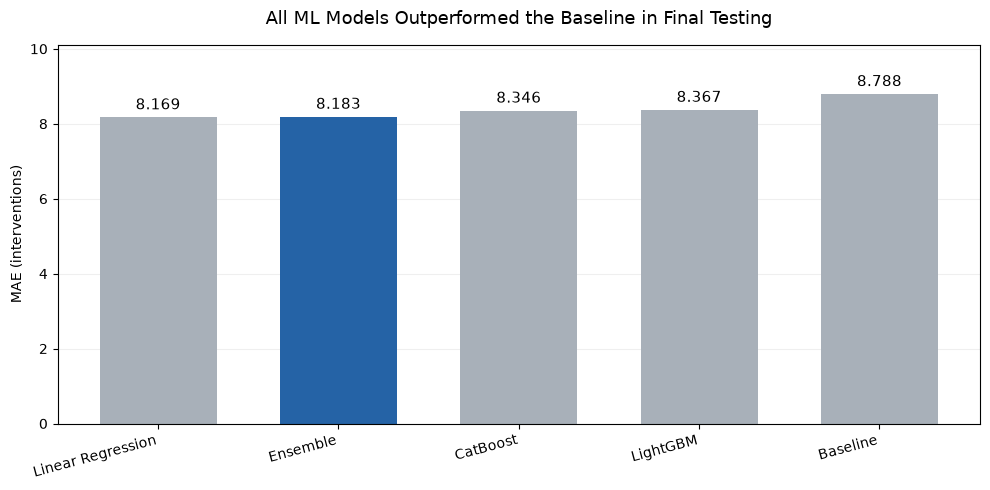

In [ ]:

model_columns = {
    "Baseline": "Baseline_Prediction",
    "Linear Regression": "Linear_Prediction",
    "LightGBM": "LightGBM_Prediction",
    "CatBoost": "CatBoost_Prediction",
    "Ensemble": "Ensemble_Prediction"
}

def calculate_metrics(frame, model_name, prediction_column):
    error = frame[prediction_column] - frame[TARGET_COL]
    return {
        "Model": model_name,
        "Rows": len(frame),
        "MAE": error.abs().mean(),
        "Bias": error.mean(),
        "Error_SD": error.std(ddof=0),
        "Error_Variance": error.var(ddof=0)
    }

summary = pd.DataFrame([
    calculate_metrics(predictions, name, col)
    for name, col in model_columns.items()
])

baseline_mae = summary.loc[
    summary["Model"] == "Baseline", "MAE"
].iloc[0]

summary["MAE_Improvement_vs_Baseline_pct"] = (
    100 * (baseline_mae - summary["MAE"]) / baseline_mae
)

# Overall performance comparison
summary_sorted = summary.sort_values("MAE")

print("Final test comparison (lower MAE is better):")
display(summary_sorted.round(3))

# Final test MAE visualization
colors = [
    "#2563A6" if model == "Ensemble" else "#A8B0B9"
    for model in summary_sorted["Model"]
]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    summary_sorted["Model"],
    summary_sorted["MAE"],
    color=colors,
    width=0.65
)

# Display the MAE above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.12,
        f"{height:.3f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title(
    "All ML Models Outperformed the Baseline in Final Testing",
    fontsize=13,
    pad=15
)

plt.ylabel("MAE (interventions)")
plt.ylim(0, summary_sorted["MAE"].max() * 1.15)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()



### Methodological Observation

The final test evaluation covered 3,792 division-day observations from January 2025 through September 2026.

The selected Fixed Equal-Weight Ensemble achieved an MAE of 8.183 interventions, compared with 8.788 for the Baseline. This represents a 6.894% reduction in MAE and meets the project's primary technical success criterion.

Linear Regression achieved the lowest test MAE (8.169), slightly outperforming the Ensemble (8.183). The difference was only 0.014 interventions per prediction.

This result differs from the validation period, where the Ensemble achieved the lowest overall MAE. The selected Ensemble remains the primary method for final evaluation because its selection was established before testing.

All three Machine Learning models and the Ensemble showed negative Bias, indicating average underprediction. The Baseline had a smaller absolute Bias but higher MAE and error variability.

These findings show that the selected Ensemble improved average forecasting accuracy compared with the Baseline. However, its performance advantage is not uniform across models, and lower MAE does not necessarily imply better identification of unusually high-demand days.

Further evaluation by division, year, and demand level is needed to understand these differences and the limitations of the forecasting approach.



## 7.10 Evaluate Performance by Division and Year

This section examines whether the overall forecasting performance observed in Section 7.9 is consistent across SIM's six operational divisions and the two calendar years included in the final test period.

The same five forecasting methods are evaluated using MAE, Bias, error standard deviation, and error variance.

Performance by division helps identify differences in forecasting accuracy and systematic prediction errors across operational areas.

Performance by year helps examine changes between 2025 and 2026. The 2026 evaluation covers January 1 through September 24, while 2025 covers a complete calendar year.

These results provide a more detailed assessment of the selected Ensemble and help identify limitations that may not be visible in the overall evaluation.


In [ ]:
division_metrics = pd.DataFrame([
    {"DIVISION": division, **calculate_metrics(group, name, col)}
    for division, group in predictions.groupby("DIVISION")
    for name, col in model_columns.items()
])

predictions["Year"] = predictions["Date"].dt.year
year_metrics = pd.DataFrame([
    {"Year": year, **calculate_metrics(group, name, col)}
    for year, group in predictions.groupby("Year")
    for name, col in model_columns.items()
])

print("By division:")
display(division_metrics.round(3))
print("By year (2026 is incomplete):")
display(year_metrics.round(3))

By division:


,DIVISION,Model,Rows,MAE,Bias,Error_SD,Error_Variance
0,1,Baseline,632,6.004,0.454,10.482,109.863
1,1,Linear Regression,632,6.045,-0.384,10.497,110.188
2,1,LightGBM,632,6.145,0.268,10.479,109.807
3,1,CatBoost,632,6.167,0.144,10.588,112.100
4,1,Ensemble,632,6.016,0.009,10.437,108.930
5,2,Baseline,632,8.911,0.356,11.623,135.102
6,2,Linear Regression,632,8.239,-1.108,11.043,121.955
7,2,LightGBM,632,8.444,-0.875,11.462,131.373
8,2,CatBoost,632,8.293,-0.626,11.168,124.730
9,2,Ensemble,632,8.242,-0.870,11.075,122.655


By year (2026 is incomplete):


,Year,Model,Rows,MAE,Bias,Error_SD,Error_Variance
0,2025,Baseline,2190,8.636,-0.074,11.258,126.735
1,2025,Linear Regression,2190,8.280,-1.995,10.729,115.113
2,2025,LightGBM,2190,8.564,-2.659,11.222,125.924
3,2025,CatBoost,2190,8.552,-2.850,11.020,121.450
4,2025,Ensemble,2190,8.326,-2.501,10.759,115.756
5,2026,Baseline,1602,8.997,0.661,12.384,153.367
6,2026,Linear Regression,1602,8.016,-0.330,11.486,131.919
7,2026,LightGBM,1602,8.098,0.544,11.548,133.364
8,2026,CatBoost,1602,8.065,0.502,11.484,131.892
9,2026,Ensemble,1602,7.987,0.238,11.418,130.365


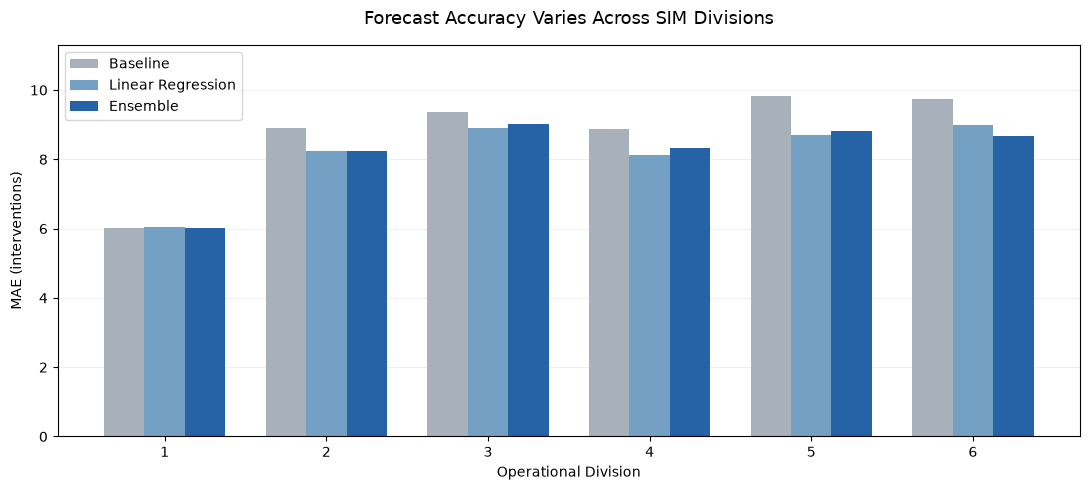

In [ ]:

# MAE comparison by operational division
selected_models = [
    "Baseline",
    "Linear Regression",
    "Ensemble"
]

mae_by_division = division_metrics[
    division_metrics["Model"].isin(selected_models)
].pivot(
    index="DIVISION",
    columns="Model",
    values="MAE"
)

divisions = mae_by_division.index
x = np.arange(len(divisions))
width = 0.25

plt.figure(figsize=(11, 5))

plt.bar(
    x - width,
    mae_by_division["Baseline"],
    width,
    label="Baseline",
    color="#A8B0B9"
)

plt.bar(
    x,
    mae_by_division["Linear Regression"],
    width,
    label="Linear Regression",
    color="#74A0C3"
)

plt.bar(
    x + width,
    mae_by_division["Ensemble"],
    width,
    label="Ensemble",
    color="#2563A6"
)

plt.title(
    "Forecast Accuracy Varies Across SIM Divisions",
    fontsize=13,
    pad=15
)

plt.xlabel("Operational Division")
plt.ylabel("MAE (interventions)")
plt.xticks(x, divisions)
plt.ylim(0, mae_by_division[selected_models].max().max() * 1.15)
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()



### Methodological Observation

The division-level evaluation shows that the selected Ensemble achieved a lower MAE than the Baseline in five of the six operational divisions.

The largest relative improvements were observed in Division 6 (11.11%) and Division 5 (10.16%). In Division 1, the Ensemble MAE (6.016) was slightly higher than the Baseline MAE (6.004).

Linear Regression achieved a lower MAE than the Ensemble in Divisions 2, 3, 4, and 5. The Ensemble performed better in Divisions 1 and 6. This confirms that no single method achieved the lowest MAE in every division.

The Ensemble also showed different prediction biases across divisions. Its largest average underpredictions occurred in Division 6 (Bias = −2.803) and Division 3 (Bias = −2.066).

The annual evaluation showed an Ensemble MAE of 8.326 in 2025 and 7.987 during the evaluated period of 2026. Its improvement over the Baseline was approximately 3.59% in 2025 and 11.23% in 2026.

The Ensemble Bias changed from −2.501 in 2025 to +0.238 in 2026, indicating a change from average underprediction to slight average overprediction.

However, 2025 covers a complete calendar year, while 2026 ends on September 24. Differences between these periods should not be interpreted as evidence of improving model performance over time without accounting for their different seasonal coverage.

Overall, these results show that the Ensemble's accuracy and prediction bias vary across divisions and evaluation periods. The global MAE improvement does not guarantee consistent performance in every operational division or reliable identification of unusually high-demand days.



## 7.11 High-Demand Comparison Using the Stage 6 Definition

This section evaluates forecasting accuracy and high-demand warning detection using the same historical threshold definition established in Stage 6.

High demand is defined separately for each operational division using the 90th percentile of historical intervention counts available through each monthly training cutoff.

The thresholds are updated monthly and remain fixed throughout each test month. An observation is classified as High when its actual or predicted count is greater than or equal to the corresponding historical threshold.

Two evaluations are performed:

1. **Forecasting accuracy on actual High demand days:** MAE and Bias are calculated using observations retrospectively classified as High based on their actual intervention counts.
2. **High-demand warning detection:** Recall and Precision measure how effectively predicted counts identify actual High demand observations.

The thresholds are calculated without using future observations or test performance results.

This evaluation preserves the methodology used in Stage 6. The separate 91-day rolling threshold rule proposed in the Business Problem Framing is evaluated in Section 7.12.


In [ ]:
monthly_threshold_records = []

for month_start in test_months:
    cutoff = month_start - pd.Timedelta(days=3)
    training_data = df.loc[
        (df["Date"] <= cutoff) & df[TARGET_COL].notna()
    ]
    division_thresholds = training_data.groupby("DIVISION")[TARGET_COL].quantile(0.90)
    for division, threshold in division_thresholds.items():
        monthly_threshold_records.append({
            "Test_Month": month_start.strftime("%Y-%m"),
            "DIVISION": division,
            "Stage6_High_Threshold": threshold
        })

monthly_thresholds = pd.DataFrame(monthly_threshold_records)
predictions["Test_Month"] = predictions["Date"].dt.strftime("%Y-%m")
predictions = predictions.merge(
    monthly_thresholds, on=["Test_Month", "DIVISION"],
    how="left", validate="many_to_one"
)
assert predictions["Stage6_High_Threshold"].notna().all()

predictions["Stage6_Actual_High"] = (
    predictions[TARGET_COL] >= predictions["Stage6_High_Threshold"]
)

stage6_high_rows = predictions.loc[predictions["Stage6_Actual_High"]]
stage6_high_mae = pd.DataFrame([
    calculate_metrics(stage6_high_rows, name, col)
    for name, col in model_columns.items()
])

stage6_warning_results = []
for name, col in model_columns.items():
    predicted_high = predictions[col] >= predictions["Stage6_High_Threshold"]
    actual_high = predictions["Stage6_Actual_High"]
    correct = int((predicted_high & actual_high).sum())
    total_alerts = int(predicted_high.sum())
    total_high = int(actual_high.sum())
    stage6_warning_results.append({
        "Model": name,
        "Warnings": total_alerts,
        "Correct_Warnings": correct,
        "Recall": correct / total_high if total_high else np.nan,
        "Precision": correct / total_alerts if total_alerts else np.nan
    })
stage6_warning_metrics = pd.DataFrame(stage6_warning_results)

print("Stage 6 definition: actual High demand days:", len(stage6_high_rows))
print("MAE on actual High demand days:")
display(stage6_high_mae.sort_values("MAE").round(3))
print("High demand warning detection:")
display(stage6_warning_metrics.round(3))

Stage 6 definition: actual High demand days: 822
MAE on actual High demand days:


,Model,Rows,MAE,Bias,Error_SD,Error_Variance
0,Baseline,822,13.922,-13.588,11.525,132.837
1,Linear Regression,822,14.671,-14.426,11.442,130.913
4,Ensemble,822,15.046,-14.914,11.202,125.495
2,LightGBM,822,15.222,-14.975,11.366,129.178
3,CatBoost,822,15.449,-15.342,11.305,127.792


High demand warning detection:


,Model,Warnings,Correct_Warnings,Recall,Precision
0,Baseline,309,153,0.186,0.495
1,Linear Regression,264,156,0.190,0.591
2,LightGBM,264,165,0.201,0.625
3,CatBoost,246,158,0.192,0.642
4,Ensemble,237,149,0.181,0.629


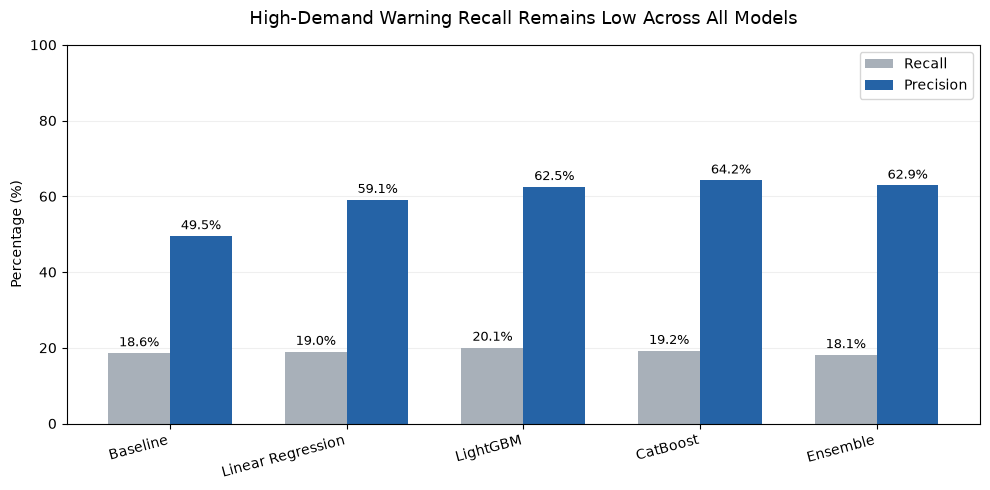

In [ ]:

# High-demand warning performance comparison
warning_plot = stage6_warning_metrics.copy()

warning_plot["Recall_pct"] = warning_plot["Recall"] * 100
warning_plot["Precision_pct"] = warning_plot["Precision"] * 100

x = np.arange(len(warning_plot))
width = 0.35

plt.figure(figsize=(10, 5))

recall_bars = plt.bar(
    x - width / 2,
    warning_plot["Recall_pct"],
    width,
    label="Recall",
    color="#A8B0B9"
)

precision_bars = plt.bar(
    x + width / 2,
    warning_plot["Precision_pct"],
    width,
    label="Precision",
    color="#2563A6"
)

for bars in [recall_bars, precision_bars]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1,
            f"{height:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.title(
    "High-Demand Warning Recall Remains Low Across All Models",
    fontsize=13,
    pad=15
)

plt.ylabel("Percentage (%)")
plt.xticks(x, warning_plot["Model"], rotation=15, ha="right")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()



### Methodological Observation

Using the historical monthly P90 thresholds established in Stage 6, the final test identified 822 actual High demand observations out of 3,792 division-day observations (21.7%).

The proportion of actual High demand observations exceeds 10% because the thresholds were calculated from historical training data rather than the test distribution. The use of a greater than or equal to comparison may also influence this proportion.

During actual High demand days, the Baseline achieved the lowest MAE (13.922), while the selected Ensemble achieved an MAE of 15.046. The Ensemble also showed substantial average underprediction (Bias = −14.914).

For High demand warning detection, the Ensemble generated 237 warnings, of which 149 were correct. Its Recall was 18.1% and its Precision was 62.9%.

This means that 673 of the 822 actual High demand observations were not identified by the Ensemble.

LightGBM achieved the highest Recall (20.1%), while CatBoost achieved the highest Precision (64.2%). However, all five methods detected only a small proportion of actual High demand observations.

Compared with Stage 6 validation, the Ensemble's Recall increased from approximately 8.6% to 18.1%, and its Precision increased from approximately 51.7% to 62.9%. These differences describe performance across different evaluation periods and do not establish a consistent improvement over time.

The results demonstrate that better overall forecasting accuracy does not necessarily produce reliable High demand warnings.

The monthly historical P90 thresholds used in this section are distinct from the 91-day rolling threshold rule proposed in the Business Problem Framing. That rule is evaluated separately in Section 7.12.

The findings support the Ensemble's improvement in overall MAE but do not establish its suitability as a reliable operational High demand alert system.



## 7.12 Evaluate the 91-Day Rolling High/Low Rule

This section evaluates the High, Normal, and Low demand classification rule proposed in the Business Problem Framing.

For each division and forecast date, two thresholds are calculated from the preceding 91 calendar days of historical intervention counts, ending at D−3:

- **High threshold:** 90th percentile (P90).
- **Low threshold:** 10th percentile (P10).

The thresholds are updated for each forecast date and calculated separately for each operational division.

The initial implementation uses inclusive comparisons:

- **High:** Count greater than or equal to P90.
- **Low:** Count less than or equal to P10.
- **Normal:** Count between the two thresholds.

A separate consistency check examines strict comparisons (`> P90` and `< P10`) to match the wording of the original Business Problem Framing. Both implementations and their results are preserved.

Missing historical counts are excluded from the percentile calculations rather than replaced with zero.

The evaluation reports actual demand category distributions and assesses High and Low warning detection using Recall and Precision.

This rolling 91-day approach differs from the monthly expanding-history thresholds evaluated in Section 7.11. The two approaches use different historical reference windows and must be interpreted separately.


In [ ]:
rolling_thresholds = []
for row in predictions[["Date", "DIVISION"]].itertuples(index=False):
    cutoff = row.Date - pd.Timedelta(days=3)
    first_day = cutoff - pd.Timedelta(days=90)
    valid_counts = history.loc[
        (history["DIVISION"] == row.DIVISION)
        & history["Date"].between(first_day, cutoff),
        TARGET_COL
    ].dropna()
    rolling_thresholds.append({
        "Low_Threshold_91d": valid_counts.quantile(0.10),
        "High_Threshold_91d": valid_counts.quantile(0.90),
        "Valid_History_91d": len(valid_counts)
    })

predictions = pd.concat([
    predictions.reset_index(drop=True), pd.DataFrame(rolling_thresholds)
], axis=1)
assert predictions[["Low_Threshold_91d", "High_Threshold_91d"]].notna().all().all()
assert predictions["Valid_History_91d"].between(1, 91).all()

def classify_demand(values, low, high):
    return np.where(
        values >= high, "High",
        np.where(values <= low, "Low", "Normal")
    )

predictions["Actual_Category_91d"] = classify_demand(
    predictions[TARGET_COL], predictions["Low_Threshold_91d"],
    predictions["High_Threshold_91d"]
)

alert_results_91d = []
for name, col in model_columns.items():
    predicted_labels = classify_demand(
        predictions[col], predictions["Low_Threshold_91d"],
        predictions["High_Threshold_91d"]
    )
    predictions[f"Alert_91d_{name.replace(' ', '_')}"] = predicted_labels
    actual_high = predictions["Actual_Category_91d"] == "High"
    predicted_high = predicted_labels == "High"
    correct = int((actual_high & predicted_high).sum())
    warnings = int(predicted_high.sum())
    high_days = int(actual_high.sum())
    alert_results_91d.append({
        "Model": name,
        "Actual_High_Days": high_days,
        "High_Alerts": warnings,
        "Correct_High_Alerts": correct,
        "High_Recall": correct / high_days if high_days else np.nan,
        "High_Precision": correct / warnings if warnings else np.nan
    })

alert_summary_91d = pd.DataFrame(alert_results_91d)
print("Actual 91-day demand categories:")
display(predictions["Actual_Category_91d"].value_counts())
print("91-day High demand warning performance:")
display(alert_summary_91d.round(3))

Actual 91-day demand categories:


Actual_Category_91d
Normal    2777
Low        532
High       483
Name: count, dtype: int64

91-day High demand warning performance:


,Model,Actual_High_Days,High_Alerts,Correct_High_Alerts,High_Recall,High_Precision
0,Baseline,483,5,0,0.000,0.000
1,Linear Regression,483,20,2,0.004,0.100
2,LightGBM,483,47,5,0.010,0.106
3,CatBoost,483,14,2,0.004,0.143
4,Ensemble,483,18,2,0.004,0.111


In [ ]:

# Low-demand warning performance
low_alert_results = []

actual_low = predictions["Actual_Category_91d"] == "Low"
low_days = int(actual_low.sum())

for name in model_columns:
    alert_column = f"Alert_91d_{name.replace(' ', '_')}"

    predicted_low = predictions[alert_column] == "Low"

    correct = int((actual_low & predicted_low).sum())
    alerts = int(predicted_low.sum())

    low_alert_results.append({
        "Model": name,
        "Actual_Low_Days": low_days,
        "Low_Alerts": alerts,
        "Correct_Low_Alerts": correct,
        "Low_Recall": correct / low_days if low_days else np.nan,
        "Low_Precision": correct / alerts if alerts else np.nan
    })

low_alert_summary_91d = pd.DataFrame(low_alert_results)

print("91-day Low demand warning performance:")
display(low_alert_summary_91d.round(3))


91-day Low demand warning performance:


,Model,Actual_Low_Days,Low_Alerts,Correct_Low_Alerts,Low_Recall,Low_Precision
0,Baseline,532,0,0,0.000,NaN
1,Linear Regression,532,19,8,0.015,0.421
2,LightGBM,532,37,8,0.015,0.216
3,CatBoost,532,44,12,0.023,0.273
4,Ensemble,532,38,8,0.015,0.211



### Strict Threshold Comparison

The Business Problem Framing defines High demand as a count above the historical 90th percentile and Low demand as a count below the historical 10th percentile.

The initial implementation used inclusive comparisons (`>=` and `<=`). This section evaluates the strict comparisons (`>` and `<`) to examine consistency with the original definition.

The same 91-day historical thresholds and model predictions are preserved.

This comparison was introduced after the initial final test evaluation. It is reported as a methodological consistency check, not as a new model selection or tuning procedure.

The results from both definitions are retained for transparency.



In [ ]:

# Strict High and Low demand classification
def classify_demand_strict(values, low, high):
    return np.where(
        values > high, "High",
        np.where(values < low, "Low", "Normal")
    )

predictions["Strict_Actual_Category_91d"] = classify_demand_strict(
    predictions[TARGET_COL],
    predictions["Low_Threshold_91d"],
    predictions["High_Threshold_91d"]
)

strict_results = []

for name, col in model_columns.items():
    predicted_labels = classify_demand_strict(
        predictions[col],
        predictions["Low_Threshold_91d"],
        predictions["High_Threshold_91d"]
    )

    for category in ["High", "Low"]:
        actual_category = (
            predictions["Strict_Actual_Category_91d"] == category
        )
        predicted_category = predicted_labels == category

        actual_count = int(actual_category.sum())
        alert_count = int(predicted_category.sum())
        correct_count = int(
            (actual_category & predicted_category).sum()
        )

        strict_results.append({
            "Model": name,
            "Category": category,
            "Actual_Days": actual_count,
            "Alerts": alert_count,
            "Correct_Alerts": correct_count,
            "Recall": (
                correct_count / actual_count
                if actual_count else np.nan
            ),
            "Precision": (
                correct_count / alert_count
                if alert_count else np.nan
            )
        })

strict_summary_91d = pd.DataFrame(strict_results)

print("Strict 91-day demand categories:")
display(
    predictions["Strict_Actual_Category_91d"].value_counts()
)

print("Strict 91-day High and Low warning performance:")
display(strict_summary_91d.round(3))

# Comparison of actual category counts
category_comparison = pd.DataFrame({
    "Inclusive": predictions["Actual_Category_91d"].value_counts(),
    "Strict": predictions["Strict_Actual_Category_91d"].value_counts()
}).fillna(0).astype(int)

print("Actual demand classification comparison:")
display(category_comparison)


Strict 91-day demand categories:


Strict_Actual_Category_91d
Normal    2917
Low        446
High       429
Name: count, dtype: int64

Strict 91-day High and Low warning performance:


,Model,Category,Actual_Days,Alerts,Correct_Alerts,Recall,Precision
0,Baseline,High,429,5,0,0.000,0.000
1,Baseline,Low,446,0,0,0.000,NaN
2,Linear Regression,High,429,20,2,0.005,0.100
3,Linear Regression,Low,446,19,7,0.016,0.368
4,LightGBM,High,429,47,5,0.012,0.106
5,LightGBM,Low,446,37,8,0.018,0.216
6,CatBoost,High,429,14,2,0.005,0.143
7,CatBoost,Low,446,44,11,0.025,0.250
8,Ensemble,High,429,18,2,0.005,0.111
9,Ensemble,Low,446,38,8,0.018,0.211


Actual demand classification comparison:


,Inclusive,Strict
Normal,2777,2917
Low,532,446
High,483,429



### Methodological Observation

The 91-day rolling threshold evaluation assessed the High, Normal, and Low demand classification rule proposed in the Business Problem Framing.

The initial implementation used inclusive thresholds (`>= P90` and `<= P10`). A subsequent consistency check examined strict thresholds (`> P90` and `< P10`), matching the original wording of the report.

**Threshold Definition Comparison**

The inclusive rule identified 483 High, 532 Low, and 2,777 Normal observations.

The strict rule identified 429 High, 446 Low, and 2,917 Normal observations.

A total of 140 observations changed from High or Low to Normal because their actual intervention counts were equal to the historical thresholds.

The number of alerts generated by each forecasting method remained unchanged between the two implementations. However, the number of correct Low alerts changed for some models because the actual demand categories changed.

Consequently, differences in Recall reflect changes in the number of actual High or Low observations and, for some models, changes in the number of correctly identified observations. They do not represent improvements in the forecasting models.

**High Demand Detection**

Under the strict rule, the selected Ensemble generated 18 High alerts, of which 2 were correct.

Its Recall was approximately 0.5% and its Precision was 11.1%. The Ensemble failed to identify 427 of the 429 actual High demand observations.

LightGBM achieved the highest High Recall (1.2%), but none of the evaluated methods demonstrated reliable High demand detection.

**Low Demand Detection**

Under the strict rule, the Ensemble generated 38 Low alerts, of which 8 were correct.

Its Recall was approximately 1.8% and its Precision was 21.1%. The Ensemble failed to identify 438 of the 446 actual Low demand observations.

CatBoost achieved the highest Low Recall (2.5%). The Baseline generated no Low alerts, so its Low Precision was undefined.

**Methodological Implications**

The strict threshold evaluation was introduced after the initial final test results to examine consistency with the original Business Problem Framing. Both implementations and their results were retained for transparency.

The strict rule is consistent with the original report definition, but neither threshold implementation provides reliable High or Low demand detection.

The selected Ensemble improved overall forecasting MAE compared with the Baseline, but this improvement did not translate into effective warning detection under the proposed 91-day rule.

These results demonstrate the importance of evaluating forecasting accuracy and decision-support classifications separately.

The findings do not establish operational benefits from using the proposed alerts. Further development and independent validation would be required before considering them for practical planning applications.



## 7.13 Review the Selected Ensemble Versus the Baseline

This section determines whether the Fixed Equal-Weight Ensemble selected during Stage 6 met the technical success criterion established in the Business Problem Framing.

The criterion requires the selected Ensemble to achieve a lower Mean Absolute Error (MAE) than the Baseline during the reserved final test period.

The comparison uses:

- The Ensemble selected from the 2021–2024 validation results.
- The 13-observation same-weekday Baseline selected during validation.
- Final test observations from January 1, 2025, through September 24, 2026.

The test results provide the final assessment of the previously selected forecasting approach. Model selection, configurations, and ensemble weights remain unchanged.

Technical forecasting success is evaluated separately from the effectiveness of High and Low demand warnings examined in Sections 7.11 and 7.12.


In [ ]:
ensemble_mae = summary.set_index("Model").loc["Ensemble", "MAE"]
mae_improvement = 100 * (baseline_mae - ensemble_mae) / baseline_mae

print(f"Baseline test MAE: {baseline_mae:.3f}")
print(f"Ensemble test MAE: {ensemble_mae:.3f}")
print(f"Ensemble MAE improvement vs Baseline: {mae_improvement:.2f}%")

if ensemble_mae < baseline_mae:
    print("Observation: Ensemble test MAE is lower than Baseline test MAE.")
elif ensemble_mae > baseline_mae:
    print("Observation: Ensemble test MAE is higher than Baseline test MAE.")
else:
    print("Observation: Ensemble and Baseline have equal test MAE.")

print("These test results are descriptive evidence, not grounds for retuning Stage 7.")

Baseline test MAE: 8.788
Ensemble test MAE: 8.183
Ensemble MAE improvement vs Baseline: 6.89%
Observation: Ensemble test MAE is lower than Baseline test MAE.
These test results are descriptive evidence, not grounds for retuning Stage 7.



## 7.14 Export Final Test Predictions and Evaluation Tables

This section saves the final test predictions, evaluation metrics, high and low demand classification results, and monthly training audit as CSV files.

All files are saved in `/content/sample_data/SIM_Stage7_Results/`.

The exported results include:

- Final test predictions for all five forecasting methods.
- Overall, division-level, and yearly performance metrics.
- High demand evaluation using the Stage 6 historical threshold definition.
- High and Low demand evaluations using the 91-day rolling thresholds.
- The strict threshold consistency check and comparison of demand classifications.
- Monthly training information used to verify chronological evaluation.

The exports preserve the completed evaluation results without modifying model predictions, configurations, or classification thresholds.

The files remain in the Colab runtime and must be copied to persistent storage if they need to be retained after the runtime ends.


In [ ]:

# Export final test predictions and evaluation tables
output_dir = "../../data/interim/final/SIM_Stage7_Results"
os.makedirs(output_dir, exist_ok=True)

# Preserve demand category names as a regular CSV column
category_comparison_export = (
    category_comparison
    .rename_axis("Category")
    .reset_index()
)

outputs = {
    "SIM_Stage7_Test_Predictions.csv": predictions,
    "SIM_Stage7_Overall_Metrics.csv": summary,
    "SIM_Stage7_Division_Metrics.csv": division_metrics,
    "SIM_Stage7_Year_Metrics.csv": year_metrics,
    "SIM_Stage7_Stage6_High_Demand_MAE.csv": stage6_high_mae,
    "SIM_Stage7_Stage6_High_Demand_Warnings.csv": stage6_warning_metrics,
    "SIM_Stage7_91Day_High_Demand_Alerts.csv": alert_summary_91d,
    "SIM_Stage7_91Day_Low_Demand_Alerts.csv": low_alert_summary_91d,
    "SIM_Stage7_91Day_Strict_Alerts.csv": strict_summary_91d,
    "SIM_Stage7_91Day_Category_Comparison.csv": category_comparison_export,
    "SIM_Stage7_Monthly_Training_Audit.csv": audit
}

for filename, frame in outputs.items():
    path = os.path.join(output_dir, filename)
    frame.to_csv(path, index=False)
    print("Saved:", path)

print("Output tables:", len(outputs))

# Verify that the category labels were preserved
print("Exported demand category comparison:")
display(
    pd.read_csv(
        os.path.join(
            output_dir,
            "SIM_Stage7_91Day_Category_Comparison.csv"
        )
    )
)


Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_Test_Predictions.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_Overall_Metrics.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_Division_Metrics.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_Year_Metrics.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_Stage6_High_Demand_MAE.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_Stage6_High_Demand_Warnings.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_91Day_High_Demand_Alerts.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_91Day_Low_Demand_Alerts.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_91Day_Strict_Alerts.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_91Day_Category_Comparison.csv
Saved: ../../data/interim/final/SIM_Stage7_Results/SIM_Stage7_Monthly_Training_Audit.csv
Output tables: 11
Exported demand category

,Category,Inclusive,Strict
0,Normal,2777,2917
1,Low,532,446
2,High,483,429



## 7.15 Methodological Observation and Stage Conclusion

### Technical Success Criterion

Stage 7 evaluated the Fixed Equal-Weight Ensemble selected during Stage 6 against the 13-observation same-weekday Baseline using the reserved final test period from January 1, 2025, through September 24, 2026.

The evaluation included 3,792 division-day observations across SIM's six operational divisions.

The Ensemble achieved an overall MAE of 8.183 interventions, compared with 8.788 for the Baseline. This represents a 6.89% reduction in MAE.

**The Ensemble met the technical success criterion established in the Business Problem Framing.**

Linear Regression achieved a slightly lower test MAE (8.169) than the Ensemble. However, the Ensemble remains the selected method because model selection was completed using the 2021–2024 validation results. The reserved test results were not used to change that decision.

### Performance Across Divisions and Years

The Ensemble achieved a lower MAE than the Baseline in five of the six operational divisions.

Division 1 was the exception, with an Ensemble MAE of 6.016 compared with 6.004 for the Baseline.

The Ensemble also showed differences in prediction bias across divisions, including average underprediction in Divisions 3 and 6.

The yearly evaluation showed an Ensemble MAE of 8.326 in 2025 and 7.987 in the evaluated portion of 2026.

However, 2025 covers a complete calendar year, while 2026 ends on September 24. These results do not establish that forecasting accuracy consistently improved over time.

### High Demand Evaluation Using the Stage 6 Definition

The monthly expanding-history P90 definition identified 822 actual High demand observations.

During those observations, the Baseline achieved a lower MAE (13.922) than the Ensemble (15.046).

The Ensemble also showed substantial average underprediction during actual High demand observations, with a Bias of −14.914.

For High demand warning detection, the Ensemble achieved a Recall of 18.1% and a Precision of 62.9%.

These results show that the Ensemble's improvement in overall MAE did not translate into better forecasting accuracy during actual High demand days or reliable identification of those days.

### Evaluation of the 91-Day Rolling Demand Rule

The separate 91-day rolling threshold evaluation examined the High, Normal, and Low demand classification rule proposed in the Business Problem Framing.

The initial implementation used inclusive comparisons (`>= P90` and `<= P10`).

A subsequent consistency check used strict comparisons (`> P90` and `< P10`) to match the original wording of the report.

This check was introduced after the initial test evaluation. Both implementations and their results were preserved for transparency.

Under the strict rule, the test observations were classified as:

- High: 429 observations.
- Normal: 2,917 observations.
- Low: 446 observations.

The Ensemble correctly identified only 2 of the 429 actual High observations, with a Recall of approximately 0.5% and a Precision of 11.1%.

For Low demand, the Ensemble correctly identified 8 of the 446 actual Low observations, with a Recall of approximately 1.8% and a Precision of 21.1%.

Neither the inclusive nor the strict implementation demonstrated reliable detection of High and Low demand observations.

The 91-day rolling rule and the Stage 6 monthly historical P90 definition use different reference windows and classify different observations as High. Their results must therefore be interpreted separately.

### Methodological Integrity and Reproducibility

The final test preserved the model configurations, preprocessing methods, ensemble weights, and Baseline selected during validation.

Models were retrained monthly using the expanding historical training window and the established D−3 cutoff.

Historical features were calculated using the same data availability restriction, and their temporal alignment was verified.

The six unknown intervention counts from December 31, 2024, were preserved as missing values rather than replaced with zero.

The final test was not used for model tuning, feature selection, ensemble weight optimization, or selection of warning thresholds.

The strict threshold comparison was documented as a consistency check rather than a new optimization procedure.

Final predictions, evaluation metrics, demand classification results, and monthly training audit information were exported for reproducibility.

### Limitations and Operational Interpretation

The project forecasts recorded intervention counts, not total operational workload.

The available public data do not establish staffing requirements, unit availability, incident duration, or the operational effects of changing planned activities.

The forecasting results therefore cannot demonstrate that the proposed approach would improve scheduling, resource availability, or emergency response operations.

The High and Low demand evaluations also showed that improved average forecasting accuracy does not guarantee reliable detection of unusually high or low intervention demand.

The current classification results do not provide sufficient evidence to recommend the proposed alerts for operational use.

Any future improvements to the warning approach would require a separate development and validation process, followed by an independent evaluation.

### Stage Conclusion

**Stage 7 confirmed that the selected Ensemble met the project's technical forecasting success criterion by reducing overall MAE by 6.89% compared with the Baseline.**

However, performance varied across operational divisions and demand conditions.

The Ensemble did not consistently outperform the Baseline during actual High demand observations, and the proposed 91-day High/Normal/Low classification rule demonstrated very limited warning detection.

The project therefore supports a conclusion of improved average intervention count forecasting, but not demonstrated operational effectiveness.

This distinction is essential when interpreting the results and communicating the project's contributions and limitations.
